In [1]:
import pandas as pd
import numpy as np
import scipy.stats
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Task 1: Load the Teaching Rating Dataset
df = pd.read_csv('teachingratings.csv')
df

,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof,PrimaryLast,vismin,female,single_credit,upper_division,English_speaker,tenured_prof
0,yes,36,female,more,0.289916,4.3,upper,yes,yes,24,43,1,0,1,1,0,1,1,1
1,yes,36,female,more,0.289916,3.7,upper,yes,yes,86,125,1,0,1,1,0,1,1,1
2,yes,36,female,more,0.289916,3.6,upper,yes,yes,76,125,1,0,1,1,0,1,1,1
3,yes,36,female,more,0.289916,4.4,upper,yes,yes,77,123,1,1,1,1,0,1,1,1
4,no,59,male,more,-0.737732,4.5,upper,yes,yes,17,20,2,0,0,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
458,no,37,male,more,0.933396,3.5,upper,yes,yes,15,17,40,1,0,0,0,1,1,1
459,no,58,female,more,0.111563,3.5,upper,yes,yes,26,34,47,1,0,1,0,1,1,1
460,no,42,male,more,-0.900580,4.0,upper,yes,yes,45,86,61,1,0,0,0,1,1,1
461,no,39,male,more,0.643014,4.3,upper,yes,yes,22,29,62,1,0,0,0,1,1,1


# Task 2: Does Gender Affect Teaching Evaluation? (Independent Samples t-Test)
## T2-1: State the Hypotheses
### Null Hypothesis (H0): Female and Male instructors have the same teaching evaluation scores.
### Alternative Hypothesis (H1): Female and Male instructors have different teaching evaluation scores.

In [7]:
## T2-2: Split the Dataset by Gender
male_rating_df = df['eval'][df['gender'] == 'male']
female_rating_df = df['eval'][df['gender'] == 'female']

print(male_rating_df)
print(female_rating_df)

4      4.5
5      4.0
6      2.1
7      3.7
8      3.2
      ... 
450    3.2
451    4.3
458    3.5
460    4.0
461    4.3
Name: eval, Length: 268, dtype: float64
0      4.3
1      3.7
2      3.6
3      4.4
9      4.3
      ... 
455    4.1
456    3.3
457    2.3
459    3.5
462    3.0
Name: eval, Length: 195, dtype: float64


In [8]:
## T2-3: Compute Mean and Standard Deviation
male_mean = np.mean(male_rating_df)
male_std = np.std(male_rating_df, ddof=1)
female_mean = np.mean(female_rating_df)
female_std = np.std(female_rating_df, ddof=1)
print(f"male {male_mean} {male_std}")
print(f"female {female_mean} {female_std}")

male 4.06902985163589 0.5566518074142298
female 3.901025635156876 0.5388025823261163


<Axes: xlabel='eval', ylabel='Count'>

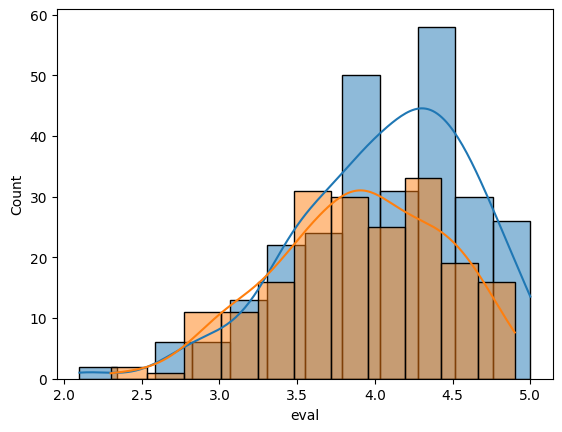

In [9]:
## T2-4: Test for Normality
### T2-4-1: Visual Inspection
sns.histplot(male_rating_df, kde=True)
sns.histplot(female_rating_df, kde=True)

## Please provide your answer in the text cell below whether the data are normally distributed.
### The histogram for both male and female ratings appear to be not normally distributed based on the visual inspection of the histograms. The histogram seems to be skewed left for both male and female ratings. Therefore, we can conclude that the data are not normally distributed.

In [10]:
### T2-4-2: Shapiro-Wilk Test
male_shapiro_test = scipy.stats.shapiro(male_rating_df)
female_shapiro_test = scipy.stats.shapiro(female_rating_df)
print(f"male {male_shapiro_test}")
print(f"female {female_shapiro_test}")

male ShapiroResult(statistic=np.float64(0.9687742582799467), pvalue=np.float64(1.3880709041665238e-05))
female ShapiroResult(statistic=np.float64(0.98163174037128), pvalue=np.float64(0.011731484258520962))


## Please provide your answer in the text cell below whether the data are normally distributed.
### Based on the Shapiro-Wilk test results, the data for both male and female ratings appear to be not normally distributed (p-values < 0.05).

In [21]:
## T2-5: Test for Equal Variances

### Please use scipy.stats.levene to test if the variances of teaching evaluation rates are equal. Specify center based on your conclusion in T2-4-1.
### Hint:
### center='mean' is used when the data are normally distributed.
### center='median' is used when the data are not normally distributed.

levene_test = scipy.stats.levene(male_rating_df, female_rating_df, center='median')
print(f"levene {levene_test}")

levene LeveneResult(statistic=np.float64(0.1194317835514822), pvalue=np.float64(0.7298092272287092))


## Please provide your answer below whether two samples have the same variances.
### P-value > 0.05, we fail to reject the null hypothesis, which means that the two samples have equal variances.

In [13]:
## T2-6: Perform the Independent Samples t-Test
ttest = scipy.stats.ttest_ind(male_rating_df, female_rating_df, equal_var=True)
print(f"t-test {ttest}")

t-test TtestResult(statistic=np.float64(3.249937943510772), pvalue=np.float64(0.0012387609449522217), df=np.float64(461.0))


## Please provide your answer below whether the gender affects teaching evaluation rating based on the t-test result.
### The gender affects teaching evaluation rating based on the t-test result. The p-value is less than 0.05, indicating that there is a statistically significant difference between the means of the two groups (male and female). We reject the null hypothesis and conclude that gender has an effect on teaching evaluation ratings.

In [15]:
## T2-7: Perform the Mann-Whitney U-Test
mannwhitneyu_test = scipy.stats.mannwhitneyu(male_rating_df, female_rating_df)
print(f"mannwhitneyu {mannwhitneyu_test}")

mannwhitneyu MannwhitneyuResult(statistic=np.float64(30911.0), pvalue=np.float64(0.0007567781189068587))


## Please provide your answer below whether the gender affects teaching evaluation rating based on the Mann-Whitney U-Test result.
### The Mann-Whitney U-Test result shows a p-value of 0.0007, which is less than the significance level of 0.05. Therefore, we reject the null hypothesis and conclude that there is a statistically significant difference in teaching evaluation ratings between male and female instructors. This suggests that gender does affect teaching evaluation ratings.

In [16]:
# Task 3: Does Teaching Evaluation Differ by Age? (One-way ANOVA)
## T3-1: Split the Dataset by Age Group
young_rating_df = df.loc[(df['age'] <= 40), 'eval']
mid_rating_df = df.loc[(df['age'] > 40) & (df['age'] < 57), 'eval']
old_rating_df = df.loc[(df['age'] >= 57), 'eval']

In [17]:
## T3-2: Compute Mean and Standard Deviation for Each Group
young_mean = np.mean(young_rating_df)
young_std = np.std(young_rating_df, ddof=1)
mid_mean = np.mean(mid_rating_df)
mid_std = np.std(mid_rating_df, ddof=1)
old_mean = np.mean(old_rating_df)
old_std = np.std(old_rating_df, ddof=1)
print(f"young {young_mean} {young_std}")
print(f"mid {mid_mean} {mid_std}")
print(f"old {old_mean} {old_std}")

young 4.002654871054455 0.5057632493708224
mid 4.030701748111792 0.5379234358312474
old 3.9336065581587496 0.6242497286958886


In [18]:
## T3-3: Test for Equal Variances
levene_test_age = scipy.stats.levene(young_rating_df, mid_rating_df, old_rating_df, center='mean')
print(f"levene {levene_test_age}")

levene LeveneResult(statistic=np.float64(3.820237661494229), pvalue=np.float64(0.02262141852021939))


## Please provide your answer below whether the variances are the same or different.
### The variances are different because the p-value is less than 0.05. Which means we reject the null hypothesis that the variances are equal.

In [20]:
## T3-4: Perform One-way ANOVA
anova_test = scipy.stats.f_oneway(young_rating_df, mid_rating_df, old_rating_df)
print(f"anova {anova_test}")

anova F_onewayResult(statistic=np.float64(1.222632799657221), pvalue=np.float64(0.29540894225417536))


## Please provide your answer below whether the teaching evaluation rating differs by age group.
### The teaching evaluation rating not differ by age group because the p-value is greater than 0.05, which means we fail to reject the null hypothesis.